Name: Keerthi N

Registration No: 2411021240024

University: Alliance University

Subject: Deep Learning

Topic: Overfitting and Underfitting Analysis

# Project 10: Overfitting and Underfitting Analysis

## Objective

The objective of this project is to understand underfitting, appropriate fitting, and overfitting in neural networks.

The Iris dataset is used to train neural network models with different levels of complexity. The performance of the models is compared using training and testing accuracy and loss.

Three models are created:
1. Simple Neural Network – to demonstrate underfitting
2. Medium Neural Network – to demonstrate appropriate fitting
3. Complex Neural Network – to demonstrate overfitting

In [ ]:
# Import required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.utils import to_categorical

print("All libraries imported successfully!")

All libraries imported successfully!


## 1. Loading the Iris Dataset

The Iris dataset is a classification dataset containing information about iris flowers.

It contains four input features:

- Sepal Length
- Sepal Width
- Petal Length
- Petal Width

The dataset contains three classes:

- Setosa
- Versicolor
- Virginica

In [ ]:
# Load the Iris dataset

iris = load_iris()

X = iris.data
y = iris.target

print("Dataset loaded successfully!")
print("Number of samples:", X.shape[0])
print("Number of features:", X.shape[1])
print("Class names:", iris.target_names)

Dataset loaded successfully!
Number of samples: 150
Number of features: 4
Class names: ['setosa' 'versicolor' 'virginica']


## 2. Converting the Target Variable

The target variable contains three classes represented by the numbers 0, 1, and 2.

For neural network classification, these class values are converted into one-hot encoded format.

For example:

0 → [1, 0, 0]

1 → [0, 1, 0]

2 → [0, 0, 1]

In [ ]:
# Convert target labels into one-hot encoding

y = to_categorical(y, num_classes=3)

print("One-hot encoding completed!")
print("Encoded target shape:", y.shape)

One-hot encoding completed!
Encoded target shape: (150, 3)


## 3. Splitting the Dataset

The dataset is divided into two parts:

- 80% for training
- 20% for testing

The training data is used to teach the neural network.

The testing data is used to check how well the model performs on unseen data.

In [ ]:
# Split the dataset into training and testing data

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=np.argmax(y, axis=1)
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 120
Testing samples: 30


## 4. Standardizing the Input Data

The input features have different numerical ranges.

Standardization converts the features to a similar scale.

This helps the neural network train more effectively.

In [ ]:
# Standardize the input features

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Feature standardization completed!")

Feature standardization completed!


# Model 1: Underfitting Model

## Purpose

The first model is intentionally kept very simple.

It contains only a small number of neurons.

A model with insufficient complexity may not be able to learn the important patterns in the dataset.

This condition is called underfitting.

In [ ]:
# Create a simple neural network to demonstrate underfitting

underfit_model = Sequential([
    Dense(2, activation='relu', input_shape=(4,)),
    Dense(3, activation='softmax')
])

underfit_model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("Underfitting model created!")
underfit_model.summary()

Underfitting model created!


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 2)              │            10 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19 (76.00 B)

 Trainable params: 19 (76.00 B)

 Non-trainable params: 0 (0.00 B)

## Training the Underfitting Model

The simple neural network is trained using the training dataset.

The model is trained for a limited number of epochs.

In [ ]:
# Train the underfitting model

history_underfit = underfit_model.fit(
    X_train,
    y_train,
    epochs=20,
    batch_size=16,
    validation_data=(X_test, y_test),
    verbose=1
)

print("Underfitting model training completed!")

Epoch 1/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 65ms/step - accuracy: 0.5333 - loss: 1.0534 - val_accuracy: 0.6667 - val_loss: 1.0408
Epoch 2/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.6500 - loss: 1.0473 - val_accuracy: 0.6667 - val_loss: 1.0354
Epoch 3/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.6500 - loss: 1.0412 - val_accuracy: 0.6667 - val_loss: 1.0299
Epoch 4/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.6500 - loss: 1.0347 - val_accuracy: 0.6667 - val_loss: 1.0244
Epoch 5/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.6500 - loss: 1.0288 - val_accuracy: 0.3333 - val_loss: 1.0186
Epoch 6/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.5833 - loss: 1.0222 - val_accuracy: 0.6667 - val_loss: 1.0129
Epoch 7/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.6500 - loss: 1.0156 - val_accuracy: 0.6667 - val_loss: 1.0071
Epoch 8/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.5833 - loss: 1.0089 - val_accuracy: 0.6667 - val_loss: 1.0012


## Evaluating the Underfitting Model

The model is evaluated using both training data and testing data.

Training accuracy shows how well the model learned the training data.

Testing accuracy shows how well the model performs on unseen data.

In [ ]:
# Evaluate the underfitting model

train_loss_1, train_acc_1 = underfit_model.evaluate(
    X_train,
    y_train,
    verbose=0
)

test_loss_1, test_acc_1 = underfit_model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print("UNDERFITTING MODEL")
print("------------------")
print("Training Accuracy:", train_acc_1)
print("Testing Accuracy :", test_acc_1)
print("Training Loss    :", train_loss_1)
print("Testing Loss     :", test_loss_1)

UNDERFITTING MODEL
------------------
Training Accuracy: 0.6916666626930237
Testing Accuracy : 0.699999988079071
Training Loss    : 0.9196593165397644
Testing Loss     : 0.9236958622932434


## Underfitting Model - Accuracy and Loss Graphs

The graphs below show the training and testing accuracy and loss during training.

An underfitting model generally has relatively low performance on both training and testing data.

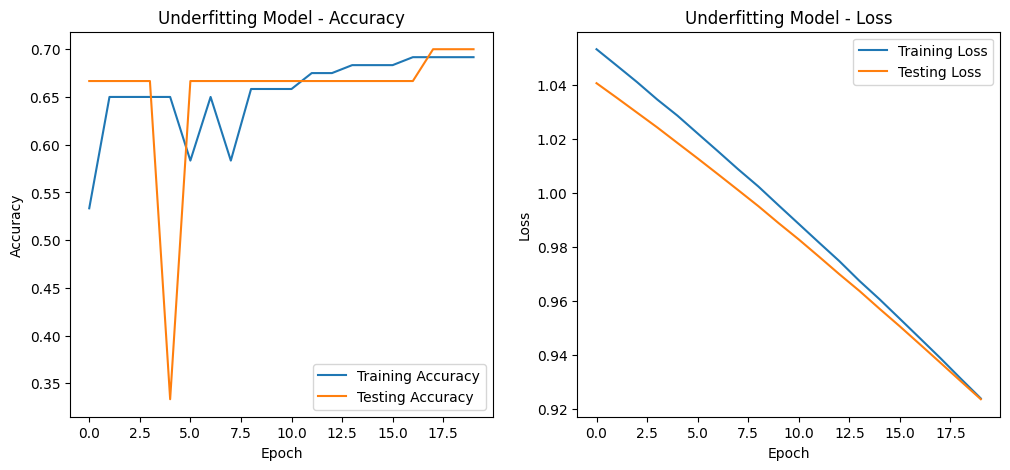

In [ ]:
# Plot accuracy and loss for the underfitting model

plt.figure(figsize=(12, 5))

# Accuracy graph
plt.subplot(1, 2, 1)

plt.plot(
    history_underfit.history['accuracy'],
    label='Training Accuracy'
)

plt.plot(
    history_underfit.history['val_accuracy'],
    label='Testing Accuracy'
)

plt.title('Underfitting Model - Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Loss graph
plt.subplot(1, 2, 2)

plt.plot(
    history_underfit.history['loss'],
    label='Training Loss'
)

plt.plot(
    history_underfit.history['val_loss'],
    label='Testing Loss'
)

plt.title('Underfitting Model - Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.show()

# Model 2: Appropriate Fitting Model

## Purpose

The second model has a moderate number of neurons and hidden layers.

The goal is to create a model that learns the important patterns in the training data while also performing well on unseen testing data.

This represents an appropriate or good fit.

In [ ]:
# Create a medium-complexity neural network

good_model = Sequential([
    Dense(16, activation='relu', input_shape=(4,)),
    Dense(8, activation='relu'),
    Dense(3, activation='softmax')
])

good_model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("Good-fitting model created!")
good_model.summary()

Good-fitting model created!


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 16)             │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 243 (972.00 B)

 Trainable params: 243 (972.00 B)

 Non-trainable params: 0 (0.00 B)

## Training the Appropriate-Fitting Model

The model is trained for more epochs than the simple model so that it has enough time to learn the patterns in the dataset.

In [ ]:
# Train the appropriate-fitting model

history_good = good_model.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=16,
    validation_data=(X_test, y_test),
    verbose=1
)

print("Good-fitting model training completed!")

Epoch 1/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 75ms/step - accuracy: 0.3667 - loss: 1.0478 - val_accuracy: 0.5667 - val_loss: 0.9963
Epoch 2/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.4750 - loss: 0.9644 - val_accuracy: 0.6333 - val_loss: 0.9211
Epoch 3/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.5833 - loss: 0.8934 - val_accuracy: 0.7000 - val_loss: 0.8547
Epoch 4/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.6583 - loss: 0.8295 - val_accuracy: 0.6667 - val_loss: 0.7996
Epoch 5/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.6750 - loss: 0.7744 - val_accuracy: 0.6667 - val_loss: 0.7531
Epoch 6/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.6667 - loss: 0.7277 - val_accuracy: 0.6667 - val_loss: 0.7113
Epoch 7/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.6667 - loss: 0.6847 - val_accuracy: 0.6667 - val_loss: 0.6751
Epoch 8/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.6667 - loss: 0.6464 - val_accuracy: 0.7000 - val_loss: 0.6441


In [ ]:
# Evaluate the good-fitting model

train_loss_2, train_acc_2 = good_model.evaluate(
    X_train,
    y_train,
    verbose=0
)

test_loss_2, test_acc_2 = good_model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print("GOOD FIT MODEL")
print("--------------")
print("Training Accuracy:", train_acc_2)
print("Testing Accuracy :", test_acc_2)
print("Training Loss    :", train_loss_2)
print("Testing Loss     :", test_loss_2)

GOOD FIT MODEL
--------------
Training Accuracy: 0.8999999761581421
Testing Accuracy : 0.8999999761581421
Training Loss    : 0.22613225877285004
Testing Loss     : 0.2732679545879364


## Appropriate-Fitting Model - Accuracy and Loss Graphs

The graphs show the training and testing performance.

For an appropriately fitted model, training and testing performance should both be good, with a relatively small difference between them.

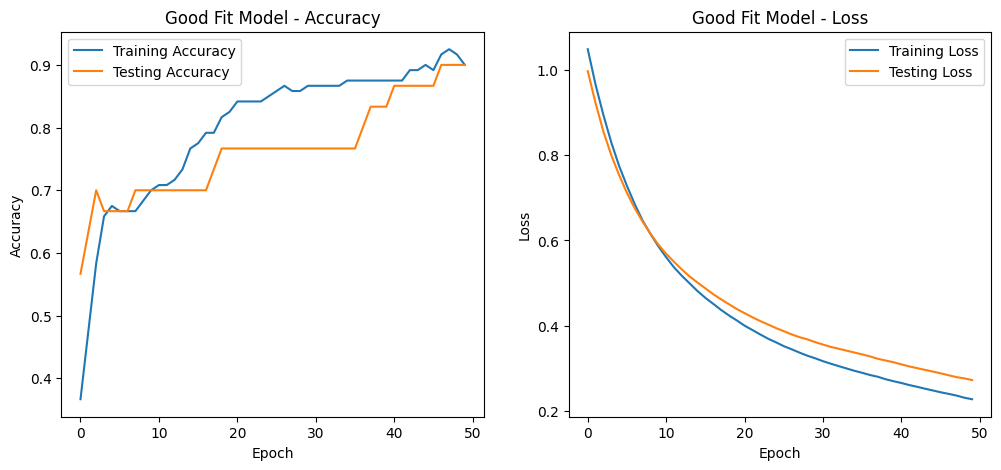

In [ ]:
# Plot accuracy and loss for the good-fitting model

plt.figure(figsize=(12, 5))

# Accuracy graph
plt.subplot(1, 2, 1)

plt.plot(
    history_good.history['accuracy'],
    label='Training Accuracy'
)

plt.plot(
    history_good.history['val_accuracy'],
    label='Testing Accuracy'
)

plt.title('Good Fit Model - Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Loss graph
plt.subplot(1, 2, 2)

plt.plot(
    history_good.history['loss'],
    label='Training Loss'
)

plt.plot(
    history_good.history['val_loss'],
    label='Testing Loss'
)

plt.title('Good Fit Model - Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.show()

# Model 3: Overfitting Model

## Purpose

The third model is intentionally made much more complex.

It contains several hidden layers and many neurons.

Because the Iris dataset is small, a very complex model can learn the training data too specifically.

This can result in very high training accuracy but comparatively lower testing performance.

This condition is called overfitting.

In [ ]:
# Create a complex neural network to demonstrate overfitting

overfit_model = Sequential([
    Dense(128, activation='relu', input_shape=(4,)),
    Dense(128, activation='relu'),
    Dense(64, activation='relu'),
    Dense(32, activation='relu'),
    Dense(3, activation='softmax')
])

overfit_model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("Overfitting model created!")
overfit_model.summary()

Overfitting model created!


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_5 (Dense)                 │ (None, 128)            │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 27,587 (107.76 KB)

 Trainable params: 27,587 (107.76 KB)

 Non-trainable params: 0 (0.00 B)

## Training the Overfitting Model

The complex model is trained for a large number of epochs.

The purpose is to observe how a highly complex model can learn the training data extremely well.

This helps demonstrate the behavior of overfitting.

In [ ]:
# Train the overfitting model

history_overfit = overfit_model.fit(
    X_train,
    y_train,
    epochs=200,
    batch_size=8,
    validation_data=(X_test, y_test),
    verbose=1
)

print("Overfitting model training completed!")

Epoch 1/200
15/15 ━━━━━━━━━━━━━━━━━━━━ 3s 39ms/step - accuracy: 0.7167 - loss: 0.9194 - val_accuracy: 0.7000 - val_loss: 0.7359
Epoch 2/200
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.7833 - loss: 0.5746 - val_accuracy: 0.7667 - val_loss: 0.5062
Epoch 3/200
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.8500 - loss: 0.4004 - val_accuracy: 0.7667 - val_loss: 0.3757
Epoch 4/200
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.8750 - loss: 0.2974 - val_accuracy: 0.7667 - val_loss: 0.3142
Epoch 5/200
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.8917 - loss: 0.2498 - val_accuracy: 0.8333 - val_loss: 0.2530
Epoch 6/200
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.9083 - loss: 0.1860 - val_accuracy: 0.9333 - val_loss: 0.1823
Epoch 7/200
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.9417 - loss: 0.1526 - val_accuracy: 0.9333 - val_loss: 0.1556
Epoch 8/200
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9667 - loss: 0.1157 - val_accuracy: 0.

In [ ]:
# Evaluate the overfitting model

train_loss_3, train_acc_3 = overfit_model.evaluate(
    X_train,
    y_train,
    verbose=0
)

test_loss_3, test_acc_3 = overfit_model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print("OVERFITTING MODEL")
print("-----------------")
print("Training Accuracy:", train_acc_3)
print("Testing Accuracy :", test_acc_3)
print("Training Loss    :", train_loss_3)
print("Testing Loss     :", test_loss_3)

OVERFITTING MODEL
-----------------
Training Accuracy: 1.0
Testing Accuracy : 0.9333333373069763
Training Loss    : 3.460359948803671e-05
Testing Loss     : 0.5423814058303833


## Overfitting Model - Accuracy and Loss Graphs

The graphs show how the training and testing performance change during training.

In an overfitting situation, the training accuracy can become very high while testing accuracy does not improve at the same rate.

The training loss may become very low while testing loss can remain higher.

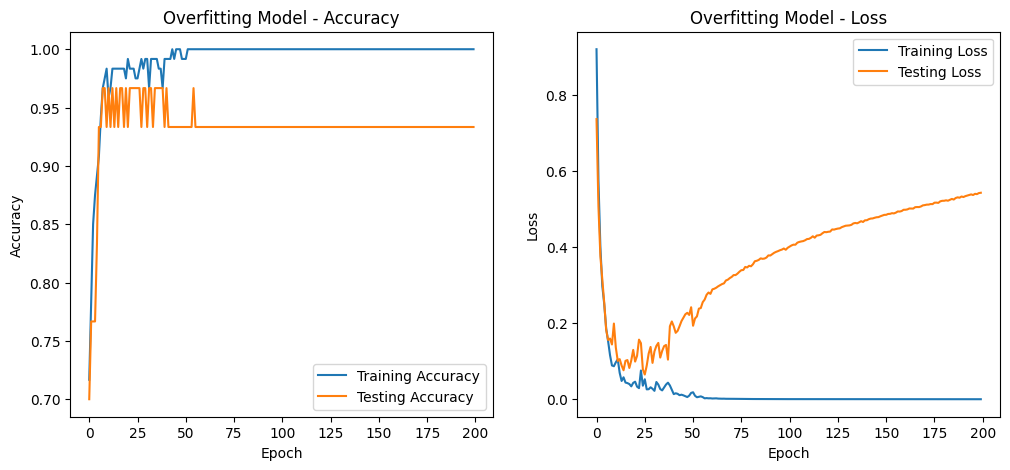

In [ ]:
# Plot accuracy and loss for the overfitting model

plt.figure(figsize=(12, 5))

# Accuracy graph
plt.subplot(1, 2, 1)

plt.plot(
    history_overfit.history['accuracy'],
    label='Training Accuracy'
)

plt.plot(
    history_overfit.history['val_accuracy'],
    label='Testing Accuracy'
)

plt.title('Overfitting Model - Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Loss graph
plt.subplot(1, 2, 2)

plt.plot(
    history_overfit.history['loss'],
    label='Training Loss'
)

plt.plot(
    history_overfit.history['val_loss'],
    label='Testing Loss'
)

plt.title('Overfitting Model - Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.show()

# Comparison of All Three Models

The three models are now compared based on their training accuracy, testing accuracy, training loss, and testing loss.

This comparison helps us identify underfitting, appropriate fitting, and overfitting.

In [ ]:
# Create a comparison table

comparison = pd.DataFrame({
    'Model': [
        'Underfitting Model',
        'Good Fit Model',
        'Overfitting Model'
    ],

    'Training Accuracy': [
        train_acc_1,
        train_acc_2,
        train_acc_3
    ],

    'Testing Accuracy': [
        test_acc_1,
        test_acc_2,
        test_acc_3
    ],

    'Training Loss': [
        train_loss_1,
        train_loss_2,
        train_loss_3
    ],

    'Testing Loss': [
        test_loss_1,
        test_loss_2,
        test_loss_3
    ]
})

comparison

,Model,Training Accuracy,Testing Accuracy,Training Loss,Testing Loss
0,Underfitting Model,0.691667,0.700000,0.919659,0.923696
1,Good Fit Model,0.900000,0.900000,0.226132,0.273268
2,Overfitting Model,1.000000,0.933333,0.000035,0.542381


## Comparison Graph

The following graph compares the training accuracy and testing accuracy of the three models.

The difference between training and testing performance helps us understand the fitting behavior of each model.

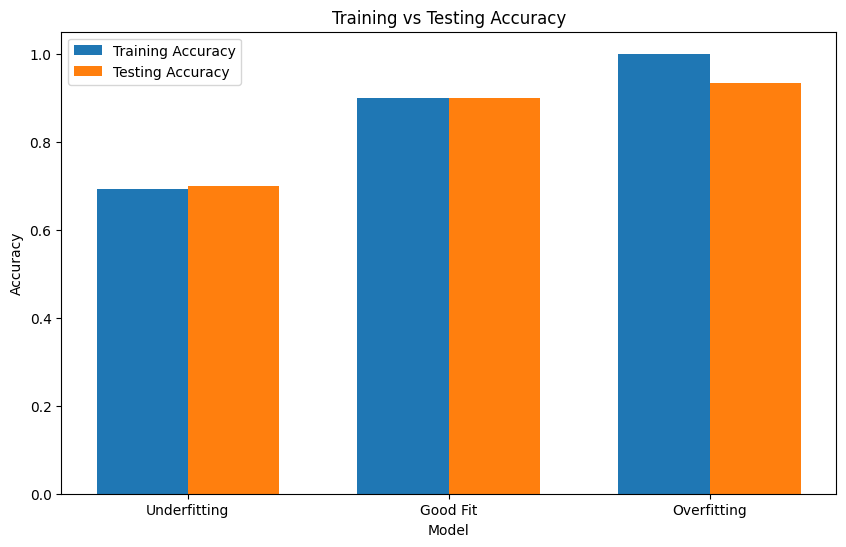

In [ ]:
# Compare training and testing accuracy

models = [
    'Underfitting',
    'Good Fit',
    'Overfitting'
]

train_accuracies = [
    train_acc_1,
    train_acc_2,
    train_acc_3
]

test_accuracies = [
    test_acc_1,
    test_acc_2,
    test_acc_3
]

x = np.arange(len(models))
width = 0.35

plt.figure(figsize=(10, 6))

plt.bar(
    x - width/2,
    train_accuracies,
    width,
    label='Training Accuracy'
)

plt.bar(
    x + width/2,
    test_accuracies,
    width,
    label='Testing Accuracy'
)

plt.xlabel('Model')
plt.ylabel('Accuracy')
plt.title('Training vs Testing Accuracy')
plt.xticks(x, models)
plt.legend()

plt.show()

# Analysis of Results

## Underfitting

The simple neural network has limited capacity because it contains very few neurons.

Therefore, it may not learn the important patterns in the Iris dataset effectively.

When both training and testing performance are relatively low, the model is considered underfitting.

## Appropriate Fitting

The medium-complexity neural network has a suitable architecture.

It learns the important patterns from the training data and also performs well on the testing data.

A small difference between training and testing performance indicates good generalization.

Therefore, this model represents an appropriate fit.

## Overfitting

The complex neural network has many neurons and hidden layers and is trained for many epochs.

It can learn the training data extremely well.

However, if the training accuracy is much higher than the testing accuracy, the model is overfitting.

This means that the model has learned the training examples too specifically and does not generalize as well to unseen data.

# Methods to Improve the Models

## Improving Underfitting

Underfitting can be reduced by:

1. Increasing the number of neurons.
2. Adding more hidden layers.
3. Training the model for more epochs.
4. Using a more suitable neural network architecture.
5. Improving the input features.

## Improving Overfitting

Overfitting can be reduced by:

1. Reducing the number of neurons.
2. Reducing the number of hidden layers.
3. Using dropout.
4. Using L1 or L2 regularization.
5. Using early stopping.
6. Increasing the amount of training data.
7. Reducing the number of training epochs.

# Final Conclusion

In this project, three neural network models with different levels of complexity were trained using the Iris dataset.

The simple model demonstrated underfitting because its limited capacity made it difficult to learn the dataset effectively.

The medium-complexity model provided a better balance between training and testing performance and represented an appropriate fit.

The complex model demonstrated overfitting because it was capable of learning the training data very closely, which can result in a large difference between training and testing performance.

Therefore, this project demonstrates that selecting the correct model complexity is important.

A good machine learning model should learn the important patterns in the training data while also performing well on unseen testing data.

## Key Learning

Underfitting → Model is too simple → Poor training and testing performance.

Good Fit → Model has suitable complexity → Good training and testing performance.

Overfitting → Model is too complex → Very high training performance but comparatively poorer testing performance.

The goal is to build a model that generalizes well to unseen data.